## **Cayden Sim-p2510893-DAAA/FT/1B/01**

## **CA1 Part A:**

---

## **Here Is a Small Background Overview:**
- This project aims to predict whether a factory machine is working or faulty based on various sensor readings and machine attributes such as ambient and process temperature, torque, rotation speed, tool wear, quality as well as product ID. 

- The dataset represents real factory conditions and supports quality control by detecting machine faults early.


## **My Planned Workflow:**
- The workflow includes data exploration, preprocessing, model building, evaluation, and improvement using *numpy*, *pandas* & *scikit-learn* classification models like KNN (K Nearest Neighbors) and Random Forest.
- Visuals and Graphs to be plotted with *Matplotlib* and *Seaborn*



---
## **Step 1**: Importing the Necessary Libraries & Their Models


In [1]:
#importing libraries and models
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
from sklearn.metrics import classification_report, accuracy_score,  precision_score, recall_score, confusion_matrix
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
import seaborn as sns
import matplotlib.pyplot as plt

- Essential libraries like pandas and numpy are imported for data handling and analysis.
- Matplotlib and Seaborn are also imported for the display of visuals and graphs.

Machine learning tools from scikit-learn such as KNeighborsClassifier, RandomForestClassifier, train_test_split, cross_val_score, KFold, GridSearchCV, LabelEncoder, StandardScaler, classification_report, accuracy_score, precision_score, recall_score, confusion_matrix are also imported to build, train, and evaluate the classification models.

---

## **Step 2:** Loading Dataset's CSV File



In [2]:
#reading dataset csv file
df = pd.read_csv("C:/Users/nedya/OneDrive/Desktop/AIML/CA1/CA1-Dataset/factory_data.csv")


- The factory dataset is loaded using pandas from a CSV file using the ***`'pd.read_csv'`*** function.



---

## **Step 3:** Exploratory Data Analysis **(EDA)**

Identifying major outliers that can affect the output of the machine.

Using a few diagrams to visualise the spread of the data per column to identify any major outliers.

Identifying missing values in columns and adding them to find the total value of the missing values.

**Numerical Columns**: Ambient & Process Temperature, Rotation Speed, Torque, Tool Wear 

**Categorical Columns**: Quality & Product ID.

For more information on the different data, refer to the visuals below.

In [3]:
print("Shape of the dataframe: ", df.shape)
print("Info on dataframe: ", df.info())


Shape of the dataframe:  (20000, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unique ID             20000 non-null  int64  
 1   Product ID            20000 non-null  object 
 2   Quality               19009 non-null  object 
 3   Ambient T (C)         20000 non-null  float64
 4   Process T (C)         19600 non-null  float64
 5   Rotation Speed (rpm)  18812 non-null  float64
 6   Torque (Nm)           20000 non-null  float64
 7   Tool Wear (min)       20000 non-null  int64  
 8   Machine Status        20000 non-null  int64  
dtypes: float64(4), int64(3), object(2)
memory usage: 1.4+ MB
Info on dataframe:  None


- From the ***`.shape`*** attribute and ***`info()`*** method outputs, we confirm that the dataset contains **`20,000 rows and 9 columns`**, with a mix of integer and float values. 

- Most columns are complete, but two features — **`Process Temperature`** and **`Rotation Speed`** — contain missing values, which will need to be addressed during preprocessing.

In [4]:
print("Here is the dataframe description: \n", df.describe())

Here is the dataframe description: 
           Unique ID  Ambient T (C)  Process T (C)  Rotation Speed (rpm)  \
count  20000.000000   20000.000000   19600.000000          18812.000000   
mean   10000.500000      26.904930      36.904291           1538.795397   
std     5773.647028       2.000834       1.483647            178.674963   
min        1.000000      22.150000      32.550000           1168.000000   
25%     5000.750000      25.250000      35.750000           1423.000000   
50%    10000.500000      26.950000      36.950000           1503.000000   
75%    15000.250000      28.450000      37.950000           1613.000000   
max    20000.000000      31.450000      40.750000           2886.000000   

        Torque (Nm)  Tool Wear (min)  Machine Status  
count  20000.000000     20000.000000    20000.000000  
mean      39.986910       107.951000        0.033900  
std        9.968684        63.652555        0.180976  
min        3.800000         0.000000        0.000000  
25%       33



- The ***`describe()`*** summary provides an overview of key statistical properties such as the mean, standard deviation, and minimum/maximum values for each numerical feature. 

- This helps identify the general ranges of the sensor readings and also highlights potential outliers, such as the unusually high maximum value in ***`Rotation Speed (rpm)`*** (2886 rpm), which stands far above the typical range. These insights guide the next steps of handling missing values and checking for abnormal patterns in the data.


---
## **Plotted Visuals:**

- To further visualise the distribution of the features, a boxplot and a correlation heatmap matrix are plotted using ***`Matplotlib`*** and ***`Seaborn`*** to provide a better understanding on the distribution of the column features' data.



## **Boxplot:**

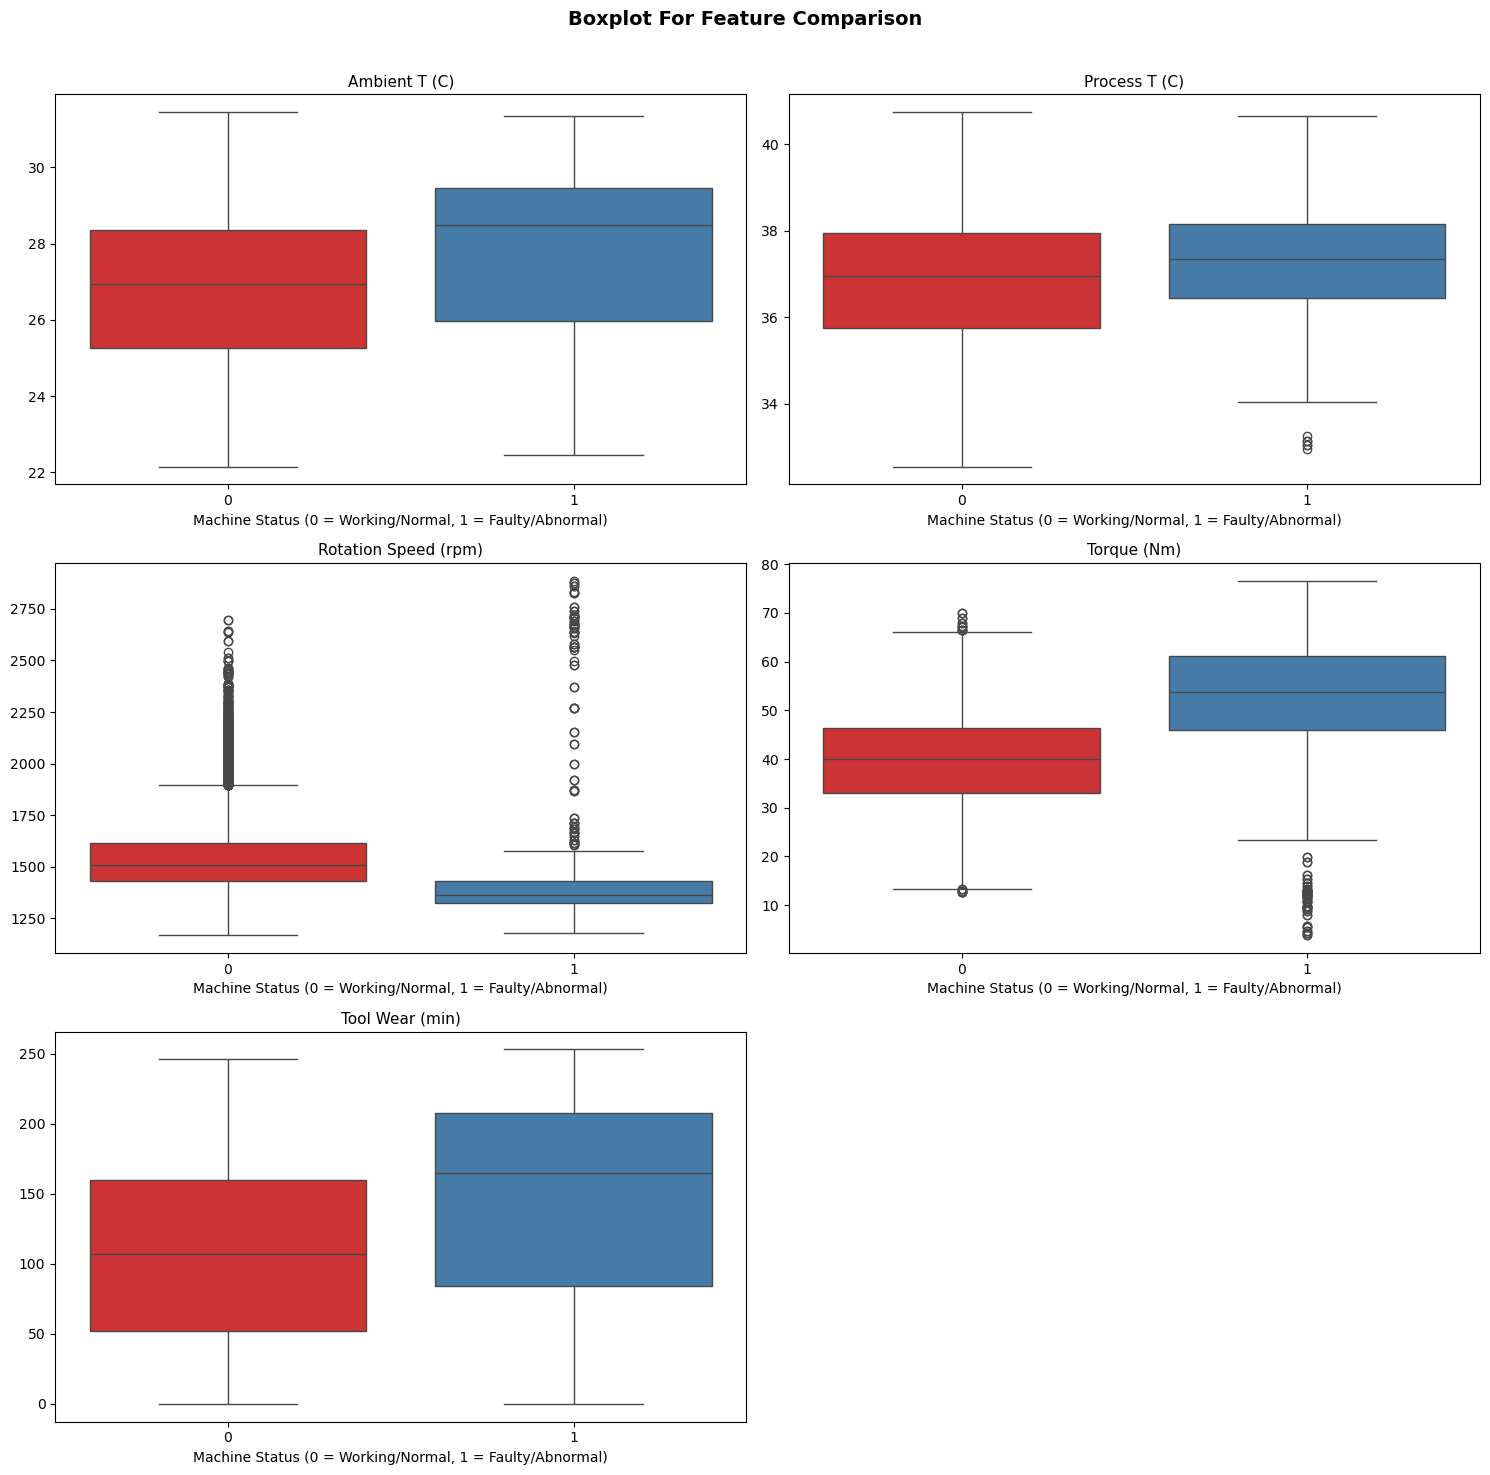

Machine Status,0,1,Difference
Tool Wear (min),106.694,143.782,37.088
Torque (Nm),39.630,50.168,10.538
Ambient T (C),26.874,27.786,0.912
Process T (C),36.894,37.190,0.296
Rotation Speed (rpm),1540.330,1495.300,-45.030


In [5]:
# Stroing the features into a list called feature_cols.
# These will be used for checking how machine behaviour differs when the status changes
feature_cols = ['Ambient T (C)', 'Process T (C)', 'Rotation Speed (rpm)', 'Torque (Nm)', 'Tool Wear (min)']

# Boxplots comparing distributions
# 15x15 gives each subplot enough space for label clarity
plt.figure(figsize=(15, 15))
plt.suptitle('Boxplot For Feature Comparison', fontsize=14, fontweight='bold')

# Boxplots help visualize spread, median, and outliers for normal vs faulty machine conditions
for i, feature in enumerate(feature_cols, 1):
    plt.subplot(3, 2, i)
    sns.boxplot(
        data=df,
        x='Machine Status',
        y=feature,
        hue='Machine Status',
        palette='Set1',
        legend=False
    )
    plt.title(feature, fontsize=11)

    # X-axis explains what each machine status number means, helpful for report readers
    plt.xlabel('Machine Status (0 = Working/Normal, 1 = Faulty/Abnormal)')

    # Y-label intentionally left blank later to avoid repeated clutter in subplot view
    plt.ylabel('')

# Adjust layout so title and plots don’t overlap
plt.tight_layout(rect=[0, 0, 1, 0.97])  
plt.show()

# Mean difference table for quick numeric insight 
feature_means = df.groupby('Machine Status')[feature_cols].mean().T

# Positive values indicate increase when machine is faulty, negative values vice-versa
feature_means['Difference'] = feature_means[1] - feature_means[0]

# Highest differences are shown at top to identify the most status-sensitive features
display(feature_means.sort_values('Difference', ascending=False).round(3))


## **Explanation:**

The boxplots above compare the distribution of each numerical feature across the two machine status groups:
- **0 = Working / Normal**
- **1 = Faulty / Abnormal**

Each sub-boxplot shows how the feature behaves for both classes, allowing for easier visual identification of patterns, spread, outliers, and possible indicators of machine failure. (Which feature will most likely cause a machine failure)

### **Some Key Observations:**
- **Process Temperature (°C)** shows a slightly higher median for faulty machines, suggesting abnormal temperature behavior may be linked to failures.
- **Rotation Speed (rpm)** appears more variable for faulty machines, showing a wider spread and more extreme values.
- **Torque (Nm)** tends to be slightly higher for faulty machines, which may indicate increased mechanical load.
- **Tool Wear (min)** is noticeably higher in faulty cases—consistent with the idea that worn tools lead to malfunction or breakdown.
- **Ambient Temperature (°C)** remains the most stable and shows minimal difference between the two classes.

###  **Why These Boxplots Matter:**
These boxplots help to identify:
- Which features differ meaningfully between normal and faulty machines  
- Potential predictors of machine status  
- Outliers that may represent early warning signs  
- How feature distributions vary across labels

This analysis provides important insights before model training and supports feature selection and understanding of fault-related behavior.


---

## **Heatmap (Correlation Matrix):**

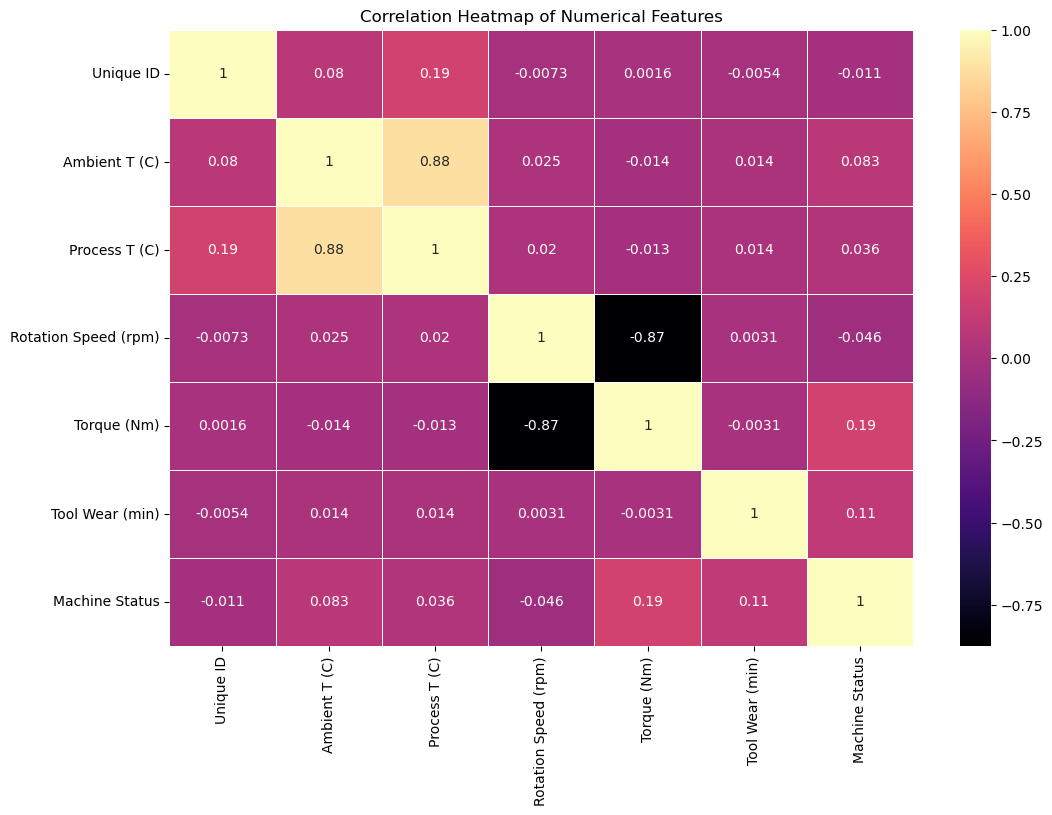

In [6]:
heatmap_cols = ["Unique ID", "Product ID" , "Ambient T (C)", "Process T (C)", "Rotation Speed (rpm)",
                "Torque (Nm)", "Tool Wear (min)", "Machine Status"]

# .corr() computes how strongly each number-based feature relates to another
# `numeric_only=True` ensures text columns aren't included to avoid errors
corr_matrix = df.corr(numeric_only=True)

#  Bigger layout makes the correlation numbers easier to read
plt.figure(figsize=(12, 8))

# `annot=True` → prints correlation values inside each cell
# The heatmap helps us quickly see strong (+1 or near) or weak (0 or near) relationships
sns.heatmap(corr_matrix, annot=True, cmap='magma', linewidths=0.5) #Temporary Color Combo

# title for heatmap
plt.title("Correlation Heatmap of Numerical Features")
# display heatmap
plt.show()

## **Explanation of Heatmap (Correlation Matrix):**

A heatmap was generated to `visualise` the `correlation` between the numerical features in the dataset.  
This helps identify how strongly each feature is related to the others.  

- Darker and brighter colors indicate stronger negative and positive correlations respectively.  

- This visualisation provides insight into which features may be more important when predicting the machine status.

- The heatmap displays which feature affects 'Machine Status' the most.

From the heatmap, it is displayed that Torque has the **`highest positive value`** of 0.19, compared to other features.

- The positive value of **`0.19`** indicates that if the torque increases, the likelihood of the outcome of 'Machine Status' to be 1 (Abnormal / Not working), is higher.

---

In [7]:
# Print the number of missing (NaN) values left in each column of the raw dataframe
print(df.isnull().sum())

Unique ID                  0
Product ID                 0
Quality                  991
Ambient T (C)              0
Process T (C)            400
Rotation Speed (rpm)    1188
Torque (Nm)                0
Tool Wear (min)            0
Machine Status             0
dtype: int64


- ***`.isnull()`*** function is used to detect any missing data in each column.
- ***`'.sum()'`*** is used as a counter to count how many entires in that column are missing data.

- By printing their combination, it reveals which columns have empty data, and how many cells in that column are empty as shown below.

This helps determine which columns require cleaning and imputation.

---

## **Step 4:** Defining The Feature Set + Preprocessing

- Text-based (object) columns are converted into numeric form using ***`'LabelEncoder()'`*** so that machine learning models can process them.

- Using **`df.drop()`** (Dropping Columns that are not needed/helpful in predicting Machine Status):
- The Unique ID and Product ID columns were dropped because they serve only as indentifiers and do not provide predictive value.

- Define **`df_model`** to contain the same set of features as **df** with the **`exclusion`** of **`'Unique ID'`** and **`'Product ID'`** columns.






In [8]:
# LabelEncoder converts text into numerical labels (0, 1)
le = LabelEncoder()
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = le.fit_transform(df[col])

 # Removing ID columns due to irrelevance & prevents models from learning misleading patterns from unique labels   
df_model = df.drop(['Unique ID', 'Product ID'], axis=1)

# Median works well because it's not affected much by outliers and keeps the central trend
for col in df_model.select_dtypes(include=[np.number]).columns:
    df_model[col] = df_model[col].fillna(df_model[col].median())

# Mode (most common value) is used to retain the existing category balance in the dataset
for col in df_model.select_dtypes(include=["object"]).columns:
    df_model[col] = df_model[col].fillna(df_model[col].mode())
print(df_model.isnull().sum())

Quality                 0
Ambient T (C)           0
Process T (C)           0
Rotation Speed (rpm)    0
Torque (Nm)             0
Tool Wear (min)         0
Machine Status          0
dtype: int64


- For **`numerical`** columns, missing data is replaced with the **`median`** of the column instead of mean as it is less affect by the presence of outliers.

- For **`categorical`** columns, missing data is replaced with the **`mode`**, which represents the most frequent value.

- The code loops through all columns to detect any empty cells and fills them accordingly — using the median for numerical columns and the mode for categorical ones.

- This is so that all missing data is properly handled and the dataset remains complete and reliable for model training and to also remove any errors due to missing cells.

## **Continuation** of **Step 4** (Explanation):
From the code above, after looping through the columns and replacing the empty values with median and mode for numerical and categorical columns respectively, when the df_model is printed out again, the column showing how many empty cells in each column of the dataset is now '0' showing that all cells in each respective column are filled with data. 

Since there are no more empty cells, the data can now be used for model training.

---

## **Step 4.5: Feature Engineering (Adding New Features)**

Before going on to Step 5, new features would be added to the current ones and displayed on a horizontal bar graph to show how external factors might also be an affecting factor of the Machine Status' outcome.

In [9]:
# Temperature Difference measures how much hotter the process is compared to surroundings
df_model['Temperature Difference'] = df_model['Process T (C)'] - df_model['Ambient T (C)']

# Thermal Load expresses process temperature relative to ambient temperature as a percentage
# Used to indicate overall heat strain on the system
df_model['Thermal Load'] = (df_model['Process T (C)'] / df_model['Ambient T (C)']) * 100

# Wear Rate estimates how fast the tool is wearing compared to rotation speed
# Helps signal abnormal wear behaviour
df_model['Wear Rate'] = df_model['Tool Wear (min)'] / df_model['Rotation Speed (rpm)']

# Stress Factor estimates mechanical stress per unit of speed
# Higher values indicate more strain at lower speeds
df_model['Stress Factor'] = df_model['Torque (Nm)'] / df_model['Rotation Speed (rpm)']

# store newly added + current features into a list
features = ["Ambient T (C)", "Process T (C)", "Rotation Speed (rpm)", "Torque (Nm)", 
            "Tool Wear (min)", "Quality", "Temperature Difference",
              "Thermal Load", "Wear Rate", "Stress Factor"
            ]
df_model[features]

,Ambient T (C),Process T (C),Rotation Speed (rpm),Torque (Nm),Tool Wear (min),Quality,Temperature Difference,Thermal Load,Wear Rate,Stress Factor
0,24.95,35.45,1551.0,42.8,0,2,10.5,142.084168,0.000000,0.027595
1,25.05,35.55,1408.0,46.3,3,1,10.5,141.916168,0.002131,0.032884
2,24.95,35.35,1498.0,49.4,5,1,10.4,141.683367,0.003338,0.032977
3,25.05,35.45,1433.0,39.5,7,1,10.4,141.516966,0.004885,0.027565
4,25.05,35.55,1408.0,40.0,9,1,10.5,141.916168,0.006392,0.028409
...,...,...,...,...,...,...,...,...,...,...
19995,25.75,35.35,1503.0,29.5,14,2,9.6,137.281553,0.009315,0.019627
19996,25.85,35.35,1632.0,31.8,17,0,9.5,136.750484,0.010417,0.019485
19997,25.95,36.95,1503.0,33.4,22,2,11.0,142.389210,0.014637,0.022222
19998,25.95,35.65,1408.0,48.5,25,0,9.7,137.379576,0.017756,0.034446


## **Description of the Newly Added Features:**

Here are the descriptions for these new Features:
- **`df['Temperature Difference']:`** 
    
    This shows the temperature difference between the process temperature and the ambient temperature. This to show how big of an increase in temperature is required for the machine to operate at from the environment's temperature. 
    
    The larger the temperature difference, the higher the stress. Stress in this case refers to the tendency of the material to expand or contract due to the change in temperature.
- **`df['Thermal Load']:`**

    This feature takes the ratio of the process temperature and the ambient temperature as a percentage to see how many times hotter the machine is compared to its surroundings.
    
- **`df['Wear Rate']:`**

    This feature measures the rate of which the machine's tool is wearing out relative to its operating speed (rpm). 

    It helps detect machines that can be wearing out faster than expected, experiencing mechanical degradation or showing ealy signs of malfunction.

    It basically displays how much wear is occurring/happening per unit of rotation (rpm).
    
    If tool wear is low and rpm is high, the machine is efficient and stable.
- **`df['Stress Factor']:`**

    This feature estimates the mechanical strain the machine experiences. It effectively represents the amount of force is required for each unit of rotatinal speed.


The new features are stored into a variable called ***`features`***, together with the original features of df_model, in a list.

---

## **Step 5:** Defining The Datasets & Splitting Datasets Into Training and Testing Using **`train_test_split`**
The **`feature set (X)`** and **`target variable (y)`** are defined — with X being equated to ***`df_model[features]`*** (Original features without 'Unique ID', and the added features), and y representing the Machine Status (Normal or Abnormal - Where 0 is normal & 1 is abnormal).

The Unique ID column is removed since it does not contribute to the prediction.

The dataset is split into 2 sets, a training set and a testing set.

The training set is used to train the models, while the testing set is used to assess how well the model was trained based on its predictions on unseen data.


In [10]:
X = df_model[features]
y = df_model["Machine Status"]

# 80% for training, 20% for testing the model’s performance on unseen data
# `random_state=42` ensures the same split every time (reproducible results)
# `stratify=y` keeps the class ratio balanced in train/test to avoid prediction bias
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42, 
                                                    stratify=y)

# StandardScaler transforms data so it has mean=0 and variance=1
# This helps distance-based and tree-based ML models perform more consistently
scaler = StandardScaler()

# `fit_transform` learns the scale values from training and applies them
# `transform` applies the learned scale without re-learning on test set (prevents data leakage)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



## **Continuation** of **Step 5** (Explanation):
From the code, the dataset is split into **`80%`** **`training data`** and **`20%`** **`testing data`**, ensuring that most of the data is used to train the model, while a smaller portion is reserved to evaluate its performance on unseen data.

***`random_state`*** was used as it is crucial for ensuring reproducibility in processes that involve randomness.

***`random_state`*** is also a seed for the random number generator, allowing consistent and repeatable results across multiple runs.

- Why Training and test data for the feature set are scaled:
    - The model can learn fairly from every feature (Where big numbers might overpower the smaller ones).
        - Model might assume larger numbers hold a higher significance over smaller numbers as the model doesn't know which numbers are important, it just sees the size of them as it is trying to check how each feature affects the results while being trained.
    - Ensures it uses the same measurement system on the testing data the model trained from.
    - Makes features a similar size for proper training.
  

---

## **Step 6:** Instantiating & Fitting Training Data 

**The First Model — K-Nearest Neighbors:**

In this step, K-Nearest Neighbors(KNN) classifier is instantiated and trained using the prepared training dataset.

The model learns the patterns between the features and the target label, machine status, by analyzing the nearest data points, which are its 'neighbors', for each sample.

In the code, variable knn is initialised to the KNearestClassifier() function, with the number of neighbors being 5.

Using .fit(), model can be fitted to the training data.

After that, predictions are made on the test dataset to evaluate how accurately the model can classify unseen data.
Predictions can be found in the next few cells.

In [11]:
#instantiate and fit to training data
# n_neighbors=5 means the model will look at the 5 closest data points in training
knn = KNeighborsClassifier(n_neighbors=5)
# stores the training data internally so the model can compute “nearest neighbors”
knn.fit(X_train_scaled, y_train)
# Results are stored in `knn_pred` for later evalutaion of metrics (accuracy, precision, recall,f1)
knn_pred = knn.predict(X_test_scaled)

---

## **Evaluation** for K-Nearest Neighbors:

The models are evaluated using: 
- Classification Report
- Confusion Matrix.

The classification report details performance for each class, and the confusion matrix visualizes correct and incorrect predictions for clearer comparison.



## **Classification Report** for K-Nearest Neighbors:
The classification report summarizes the performance of the K-Nearest Neighbors (KNN) model by showing precision, recall, and F1-score for each class.

It helps evaluate how well the model distinguishes between working and faulty machines.

In [12]:
# printing classification report for KNN
print("\tClassification Report are as follows:")
print(classification_report(y_test, knn_pred))

	Classification Report are as follows:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3864
           1       0.78      0.46      0.58       136

    accuracy                           0.98      4000
   macro avg       0.88      0.73      0.78      4000
weighted avg       0.97      0.98      0.97      4000



## **Confusion Matrix** for K-Nearest Neighbors:
The confusion matrix below visually represents the KNN model’s performance in predicting machine status.

Each cell displays the number of predictions for each actual vs. predicted class.



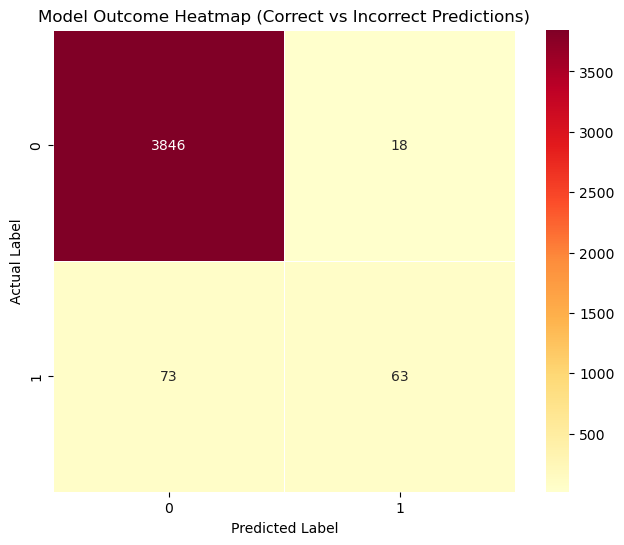

In [13]:

cm = confusion_matrix(y_test, knn_pred)


# Size is chosen to keep matrix numbers readable for analysis or presentation slides
plt.figure(figsize=(8, 6))


# `annot=True` → shows actual count values in each cell
# `fmt='d'` → formats annotations as integers (no decimals)
sns.heatmap(cm, annot=True, fmt='d',
            cmap='YlOrRd', linewidths=0.5, square=True,
            cbar=True)

# Overlay diagonal (correct predictions) to force matching color intensity


plt.title("Model Outcome Heatmap (Correct vs Incorrect Predictions)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

### **Results of the Confusion Matrix:**

- The diagonal (Top Left and Bottom Right) cells indicate correct classifications, while the off-diagonal cells (Top Right and Bottom Left) show misclassifications.

- Using Matplotlib, the confusion matrix is plotted as a heatmap with clearly labeled axes and a purple color scale for better contrast.

---

## Implementing the 2nd Model: **Random Forest**

Repeating Steps 5 & 6 but replace KNeighborsClassifier with **RandomForestClassifier**.

In this section, Steps 5 and 6 are repeated for the Random Forest model.

The model is trained and evaluated using the same dataset and metrics as before, to allow fair and equal comparison with the K-Nearest Neighbors classifier.

In [14]:
# n_estimators=100 means the model builds 100 decision trees and takes the majority vote for predictions
# random_state=42 ensures the model output is reproducible every time you run the code
rf_model = RandomForestClassifier(n_estimators=100,
                                   random_state=42) 
# The model learns patterns from X_train_scaled to predict y_train labels
rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled) 

---

## **Evaluation** for Random Forest Classifier:
Similar to the KNN model, the performance of the Random Forest model is evaluated using **Accuracy, Classification Report**, and **Confusion Matrix**.

These metrics help compare how well the Random Forest classifier performs in predicting machine status and whether it improves over the previous model.

## **Classification Report** for Random Forest:
The classification report summarizes the performance of the K-Nearest Neighbors (KNN) model by showing precision, recall, and F1-score for each class.

It helps evaluate how well the model distinguishes between working and faulty machines.

In [15]:
# prints classification report for randomforest
print("Classification Report are as follows:")
print(classification_report(y_test, rf_pred))

Classification Report are as follows:


              precision    recall  f1-score   support

           0       0.99      1.00      1.00      3864
           1       0.99      0.81      0.89       136

    accuracy                           0.99      4000
   macro avg       0.99      0.90      0.94      4000
weighted avg       0.99      0.99      0.99      4000



## **Confusion Matrix** for Random Forest:
The confusion matrix below visualizes the Random Forest model’s classification results.

Each cell shows the number of correct and incorrect predictions, with diagonal values representing accurate classifications and off-diagonal values 
indicating misclassifications.

This helps assess how well the model distinguishes between working and faulty machines.

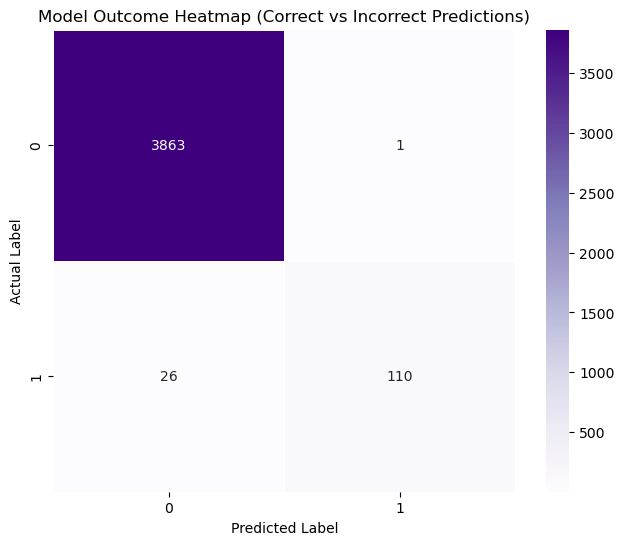

In [16]:
cm = confusion_matrix(y_test, rf_pred)


# The chosen size makes numbers inside cells readable for analysis or presentations
plt.figure(figsize=(8, 6))


# `annot=True` prints actual values inside the heatmap cells
# `fmt='d'` ensures the numbers display as whole integers
sns.heatmap(cm, annot=True, fmt='d',
            cmap='Purples', linewidths=0.5, square=True,
            cbar=True)



# These explain what the plot represents without modifying the logic of the visualization
plt.title("Model Outcome Heatmap (Correct vs Incorrect Predictions)")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

---

## Evaluations of **K-Nearest Neighbor**s & **Random Forest**:
The bar chart was created using **Matplotlib** to visually compare four key performance metrics — **Accuracy, Precision, Recall**, and **F1-Score** — between the **KNN** and **Random Forest** models.  

Each metric was represented by a different color and plotted side by side for both models.  
The values were taken directly from each model’s classification report and displayed above the bars for clarity.  


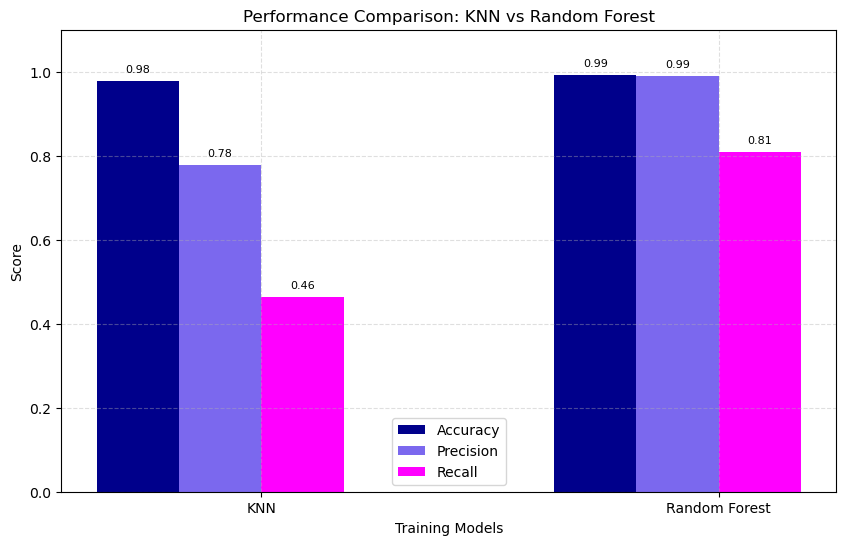

In [17]:
# list of model names
models = ['KNN', 'Random Forest']

# Metrics
# accuracy_score:  measures overall correct predictions / total predictions
# precision_score: measures how reliable the model is when it predicts the positive class
# recall_score:    measures how well the model detects the actual positive cases
knn_accuracy = accuracy_score(y_test, knn_pred)
rf_accuracy  = accuracy_score(y_test, rf_pred)

knn_precision = precision_score(y_test, knn_pred)
rf_precision  = precision_score(y_test, rf_pred)

knn_recall = recall_score(y_test, knn_pred)
rf_recall  = recall_score(y_test, rf_pred)


# Convert to lists for bar plotting
accuracy  = [knn_accuracy,  rf_accuracy]
precision = [knn_precision, rf_precision]
recall    = [knn_recall,    rf_recall]


# X positions
# np.arange creates evenly spaced positions like: [0, 1] for 2 models
x = np.arange(len(models))
width = 0.18

# Wider chart ensures metric bars + value labels are easy to read
plt.figure(figsize=(10, 6))

# Bars for each metric
# Offset positions (x -/+ width) allow metric bars to sit beside each model label
# Each metric has a different color to visually distinguish performance scores
plt.bar(x - 1.5*width, accuracy,  width, label='Accuracy',   color='darkblue')
plt.bar(x - 0.5*width, precision, width, label='Precision',  color='mediumslateblue')
plt.bar(x + 0.5*width, recall,    width, label='Recall',     color='magenta')

# Labels
# Title and axis labels explain what the plot compares
# y-range slightly above 1 ensures value labels can fit above bars
plt.title('Performance Comparison: KNN vs Random Forest')
plt.xlabel('Training Models')
plt.ylabel('Score')
plt.xticks(x, models)
plt.ylim(0, 1.1)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()

# Add values above bars:
# helps when using graph in reports or slides so viewers don't need to read matrix to know scores
# offset ensures numbers appear above the correct metric bar cluster
def add_labels(values, offset):
    for i, v in enumerate(values):
        plt.text(i + offset, v + 0.02, f"{v:.2f}", ha='center', fontsize=8)

add_labels(accuracy,  -1.5*width)
add_labels(precision, -0.5*width)
add_labels(recall,     0.5*width)

# display graph
plt.show()


---

## Here is Another Visualization:

Here is another visualization result of the comparison of the evaluations of **KNN** and **Random Forest** Models in the form of a line chart with the addition of cross validation.

This is to show across multiple folds, how accurate the overall model is.

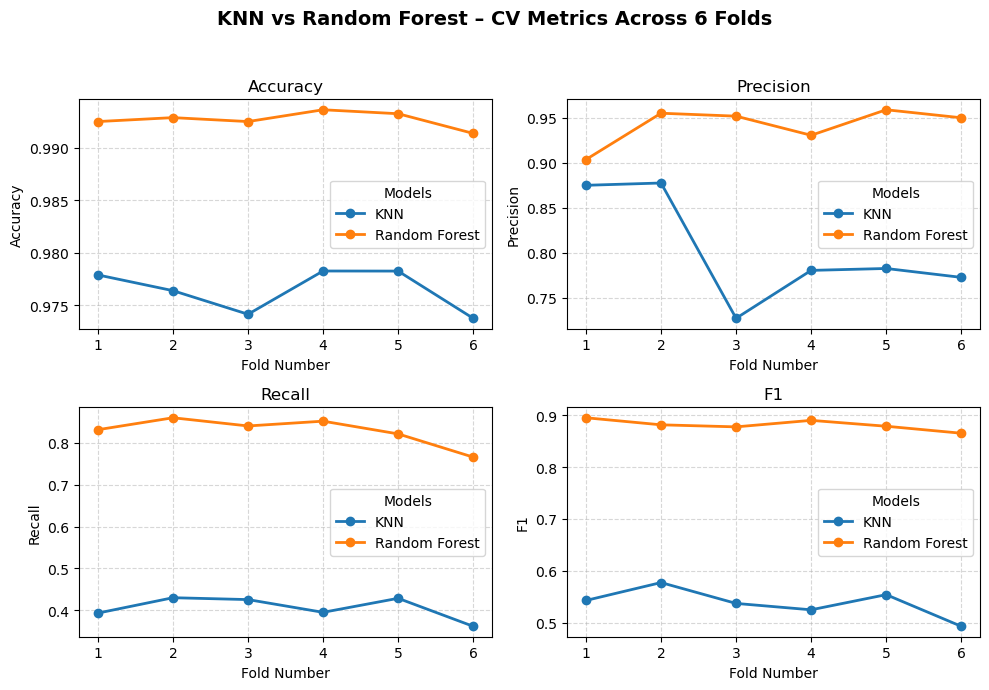

In [18]:
# define a dictionary of classification models to evaluate
models = {"KNN": KNeighborsClassifier(), "Random Forest": RandomForestClassifier()}
results = {}

# random_state ensures reproducibility, shuffle=True prevents ordered bias
# n_splits=6 means dataset will be tested 6 different times on different portions
kf = KFold(n_splits=6, random_state=42, shuffle=True)  # 6 Folds

# Collect results for each model and each metric
# cross_val_score returns an array of 6 results per metric (one per fold)
for name, model in models.items():
    results[name] = {
        "Accuracy":  cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='accuracy'),
        "Precision": cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='precision'),
        "Recall":    cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='recall'),
        "F1":        cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='f1')
    }

# Flattening allows easier iteration when plotting multiple score arrays
fig, axs = plt.subplots(2, 2, figsize=(10, 7))
axs = axs.flatten()

# Folds are labeled 1 to 6 for readability in the line charts
metrics = ["Accuracy", "Precision", "Recall", "F1"]
folds = range(1, 7)

# Overlaid line charts show performance trends and help detect instability or overfitting
for i, metric in enumerate(metrics):
    for name, metric_dict in results.items():
        cv_scores = metric_dict[metric]
        axs[i].plot(folds, cv_scores, marker='o', linewidth=2, label=name)

    # Grid makes trend spotting easier, legend separates model curves
    axs[i].set_title(metric)
    axs[i].set_xlabel("Fold Number")
    axs[i].set_ylabel(metric)
    axs[i].set_xticks(folds)
    axs[i].grid(True, linestyle='--', alpha=0.5)
    axs[i].legend(title="Models")

plt.suptitle("KNN vs Random Forest – CV Metrics Across 6 Folds", fontsize=14, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

--- 
## **Hyperparameter Tuning (Model Improvement):**

- Looking from the confusion matrix as well as the classification report of both KNN and RandomForest, it is clear that RandomForest has the better results across all metrics (accuracy, precision, recall, f1).

- Thus, in this section, the parameters of Random Forest **`(n_estimators, max_depth, max_features, etc.)`** wil be tuned to achieve the best results for the model.

- Why are hyperparameters tuned:

  - Hyperparameters are tuned because there are more optimal settings that allows the model to achieve even better results than its default settings.
  - It also makes the model more accurate and reduces overfitting.
  - Hyperparameter tuning is able to find that sweet spot between having complex data (overfitting) & too little data (underfitting). 


## **Tuning for Random Forest:**

In [19]:

param_grid = {
    'n_estimators': [50, 100, 150], # changed 200 to 150
    'max_depth': [None, 10, 20, 30], # removed 30
    'min_samples_split': [2, 5], # removed 10
    'min_samples_leaf': [1, 2], # removed 4
    'class_weight': ['balanced']
}


# 3. Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,                  # 5-fold cross validation
    scoring='recall',      # scoring metric on recall
    n_jobs=-1,             # use all processor cores (speed up gridsearch process)
    verbose=2              # show progress
)

# 4. Run the grid search
grid_search.fit(X_train_scaled, y_train)

# 5. Best hyperparameters
print("Best Hyperparameters:", grid_search.best_params_)

# 6. Best model from grid search
best_rf = grid_search.best_estimator_

# 7. Evaluate on test set
best_pred = best_rf.predict(X_test_scaled)

print("\nAccuracy:", accuracy_score(y_test, best_pred))
print("\nClassification Report:\n", classification_report(y_test, best_pred))

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best Hyperparameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 150}

Accuracy: 0.989

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.99      0.99      3864
           1       0.82      0.87      0.84       136

    accuracy                           0.99      4000
   macro avg       0.91      0.93      0.92      4000
weighted avg       0.99      0.99      0.99      4000



## **Description of GridSearchCV:**

- The estimator is the Random Forest model defined as rf_model.
- ***`param_grid`*** is the dictionary of parameters that GridSearchCV tests.
- ***`cv=5`*** defines number of folds to choose the best parameters based on highest f1 score which takes double of the product of precision and recall divided by the sum of precision and recall
- ***`n_jobs`*** tells GridSearchCV the number of CPU cores to use, ***`n_jobs=-1`*** means use all cores that are available for use, reducing the time taken to generate the output.
- ***`verbose=2`*** shows the progress and details of each parameter combination.
- ***`grid_search.fit(X_train_scaled, y_train)`*** runs entire grid search process
- ***`grid_search.best_params_`*** returns the best parameters that give the best result.
- ***`grid_search.best_estimator_`*** returns the model that has been trained using the best combination of parameters. 




## **Results of GridSearchCV:**

From the Results of ***`GridSearchCV`***, the best parameters to use for Random Forest are:
- **`'max_depth': 10`**
- **`'class_weight: 'balanced'`**
- **`'min_samples_leaf': 2`** 
- **`'min_samples_split': 2`**
- **`'n_estimators': 150`**

The classification report above evaluates the performance of the Random Forest classifier after implementing the newly tuned hyperparameter combination into the Random Forest model.  
Key metrics such as **precision**, **recall**, and **F1-score** are used to measure how well the model performs on each class.

- **Class 0 (Working Machines)** shows near-perfect performance across all metrics, showing that the model is able to correctly identify most normal working machines.
- **Class 1 (Faulty Machines)** achieves a strong improvement in recall and F1-score compared to the untuned model with a slight decrease in precision. This indicates that the tuned Random Forest is more effective at detecting faulty machinery — a critical aspect of this predictive task.

Hence, this newly tuned model provides better overall results.


---

## **Evaluation Part 2 - Comparison With a Dummy Model**

- In this part, we are comparing the 2 implemented models with a dummy model to further evaluate their performance.





### **Storing DummyClassifier, fitting and predicting the Dummy Model:**

- *`'DummyClassifier'`* is stored into a variable called *`'dummy'`*
- use *`'.fit(X_train_scaled, y_train)'`* to fit the scaled feature training data and the target training data
- use *`'.predict(X_test_scaled)'`* to predict the scaled test data for the feature set and storing it into the variable *`'dummy_pred'`*

In [20]:
# 'most_frequent' makes the model always guess the class that appears the most in training data
dummy = DummyClassifier(strategy='most_frequent')
# fit the dummy model using the scaled training data
dummy.fit(X_train_scaled, y_train)
# Stores the predicted labels of precision, accuracy, recall and f1 for later use
dummy_pred = dummy.predict(X_test_scaled)

- The *`'strategy'`* is equated to *`'most_frequent'`*. 
- This model does not learn anything and instead predicts the most frequent class, in this case, 0.
- Hence, the dummy will always predict 0.

### **Dummy's Classification Report:**

- The code block below displays the classification report of the Dummy Model.

In [21]:
# outputs the classification report for the dummy model: it includes Precision, Recall, F1-score, Accuracy
print("\tThis is the Dummy Model's classification report: \n", classification_report(y_test, dummy_pred))


	This is the Dummy Model's classification report: 
               precision    recall  f1-score   support

           0       0.97      1.00      0.98      3864
           1       0.00      0.00      0.00       136

    accuracy                           0.97      4000
   macro avg       0.48      0.50      0.49      4000
weighted avg       0.93      0.97      0.95      4000



c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\nedya\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


- To add on to the earlier markdown, from this classification report, the accuracy of the dummy is **`97%`** whereas precision, recall and f1-score for when Machine Status = 1, is **`0.00`** due the high imbalance of the dataset, where most outcomes are 0's.
- This proves that a high accuracy does NOT mean a good performance.
- This dummy replicates the scenario where a model memorises the dataset or just predicts everything is working (Machine Status = 0) in a case where almost the whole target dataset is the desired outcome.

### **Dummy Model's Confusion Matrix:**

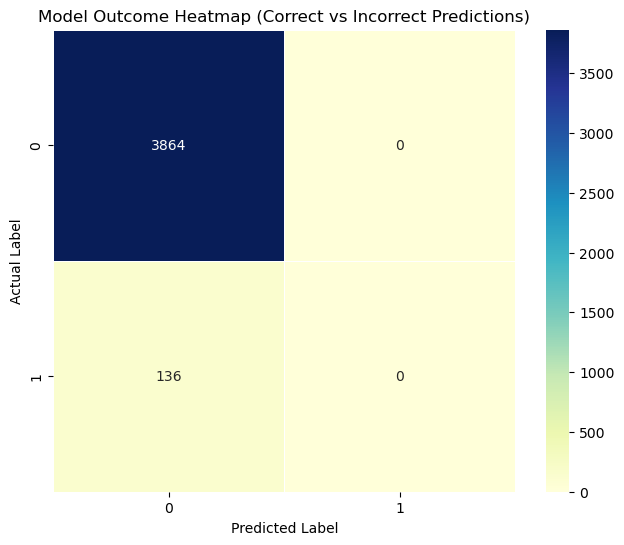

In [22]:

# Stores count of: True Positives, True Negatives, False Positives, False Negatives
cm = confusion_matrix(y_test, dummy_pred)


# A balanced size helps view matrix labels and annotations without crowding
plt.figure(figsize=(8, 6))


# Acts as the base comparison: shows where the model got predictions right or wrong
# Diagonal cells = correct predictions, off-diagonal cells = incorrect predictions
sns.heatmap(cm, annot=True, fmt='d',
            cmap='YlGnBu', linewidths=0.5, square=True,
            cbar=True)


# Title explains the purpose: highlight model baseline performance
plt.title("Model Outcome Heatmap (Correct vs Incorrect Predictions)")
plt.xlabel("Predicted Label")  # Columns show what the model predicted
plt.ylabel("Actual Label")     # Rows show the real, correct test labels

# display the matrix
plt.show()


- The confusion matrix heatmap shows that there are no instances where the model predicted 1 and the actual outcome is 0, which can be good but not in a real world scenario.
- The heatmap also shows that there are also no instances where the dummy predicted 1 and the outcome is also 1.    
- This futher highlights that although the dummy model is able to rightfully predict the instances where the outcome is 0, it does not mean that its overall performance is good and measuring it alone is misleading.


--- 
## **Comparing Dummy Model with Tuned Random Forest:**

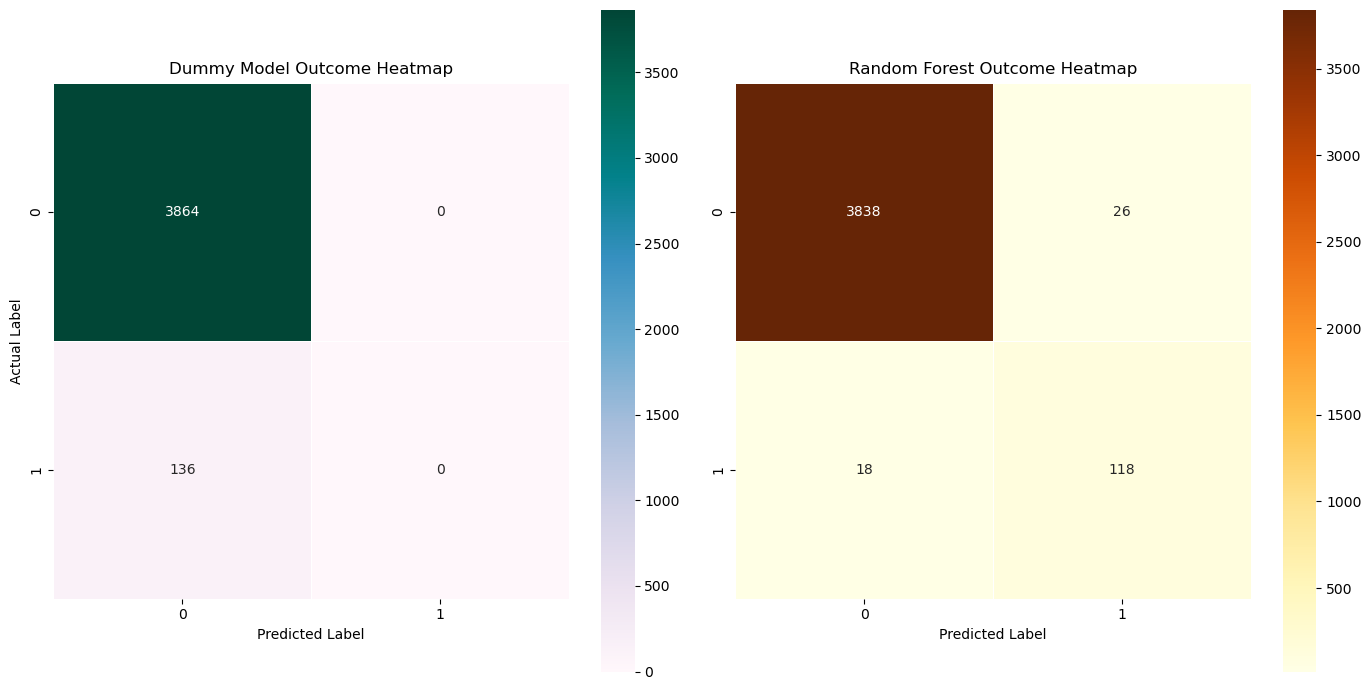

In [23]:
# Create confusion matrices for two evaluated models 
# cm_dummy: stores how the Dummy model's predictions compare against real test labels
# cm_rf:    stores how the tuned Random Forest model's predictions compare against real labels
cm_dummy = confusion_matrix(y_test, dummy_pred)
cm_rf    = confusion_matrix(y_test, best_pred)

# Initialize a wide figure to display 2 side-by-side heatmaps 
# Larger size improves readability of annotations and matrix comparison
plt.figure(figsize=(14, 7))

#  Subplot 1: Heatmap for Dummy Model confusion matrix 
# Shows baseline model behaviour, useful for understanding if learning-based models add value
plt.subplot(1, 2, 1)
sns.heatmap(cm_dummy, annot=True, fmt='d',
            cmap='PuBuGn', linewidths=0.5, square=True, cbar=True)
plt.title("Dummy Model Outcome Heatmap")
plt.xlabel("Predicted Label")  # X-axis represents model output labels
plt.ylabel("Actual Label")     # Y-axis represents the correct class labels from test data

#  Subplot 2: Heatmap for Best Random Forest Model confusion matrix 
# Allows direct visual comparison with baseline to identify model improvement and prediction quality
plt.subplot(1, 2, 2)
sns.heatmap(cm_rf, annot=True, fmt='d',
            cmap='YlOrBr', linewidths=0.5, square=True, cbar=True)
plt.title("Random Forest Outcome Heatmap")
plt.xlabel("Predicted Label")
plt.ylabel("")  # Left intentionally blank to reduce repeated labels clutter in comparison view

# --- Adjust layout so subplots don't overlap and are evenly spaced ---
plt.tight_layout()
plt.show()


---
## **Summary of Part A:**


- Implemented **`RandomForestClassifier`** & **`K-Nearest Neighbors`** models from scikit-learn.

- Evaluated the 4 models using Accuracy, Precision, Recall and F1 from the Classification Report on test data.

- `Compared` between **`Ridge`** & **`Lasso`** and displayed their metric results via bar chart and line chart.

- `Dropped` **`K-Nearest Neighbors`** due to poorer performance.

- Tuned RandomForestClassifier's parameters using GridSearchCV, yielding higher precision and recall, but f1 reduced a little.

- Compared RandomForest against a Dummy baseline to check if real learning occurred.

- Plotted a confusion matrix to visualise the comparison between Dummy & Lasso.

- Observed Dummy only predicted all '0's, where machine status is normal, hence getting all the '0' values correct, but did not predict any faulty machines correctly.

